# Analysis

The main thing we'll go through today is analysis of the Demo Experiment data. We have data from 8 participants who completed the experiment.

**Before we can start:**

**a**) [Download the demographics data](demo_demog.csv) as a `.csv` file, and place it in a directory that makes sense for you (e.g., called "demo_analysis").

**b**) [Download the stimuli](demo_stimuli.csv) as a `.csv` file, and place it in the same demo analysis folder.

**c**) [Download the raw trials data](demo_trials.zip) as a `.zip` file.

**d**) Extract the `trials` folder from the `.zip` file and put it in your demo analysis folder.

**e**) Start a new R script in RStudio, and save the `.R` file to the demo analysis folder.

After following these instructions, you should have a directory structure that looks something like this:

```
demo_analysis
├─ trials
│  ├─ trials_p03085.csv
│  ├─ trials_p05336.csv
│  └─ ...
├─ analysis.R
└─ demo_demog.csv
└─ demo_stimuli.csv
```

Once everyone has completed these steps, we'll begin...

## Loading the Data

#### 1: Load the Relevant Libraries

These are the libraries we'll use for the analysis. Each library has a comment explaining what we will use it for.

In [1]:
options(repr.plot.width=3.5, repr.plot.height=3)
library(ggplot2)
theme_set(theme_classic() + theme(legend.position="top"))

In [39]:
library(readr)    # for reading the data into R
library(purrr)    # for easily importing multiple files
library(dplyr)    # for wrangling data (e.g., adding/renaming columns)
library(afex)     # for fitting a repeated measures anova
library(emmeans)  # for summarising factorial cells

library(ggplot2)  # for visualising data

#### 2. Import the Demographic Data

First, we import the demographics data. This gives us some details about the participants who took part.

In [3]:
demog <- read_csv("demo_demog.csv")

Rows: 17 Columns: 9
-- Column specification -------------------------------------------------------------------------------------------
Delimiter: ","
chr (2): participant_id, participant_gender
dbl (7): participant_age, calibration_card_width_px, calibration_pixels_per_...

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.


This will print some details about the columns imported. Let's have a look at the data we imported. The `demog` dataframe contains details on participants' ages, genders, results from the virtual chinrest calibration, and the total time taken to complete the experimental session.

In [4]:
demog

participant_id,participant_age,participant_gender,calibration_card_width_px,calibration_pixels_per_mm,blindspot_position_mean_px,blindspot_position_sd_px,viewing_distance_mm,total_time_s
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
p18996,22,weiblich,432,5.046729,576.4400,10.934715,475.8122,674138
p58497,20,weiblich,436,5.093458,491.2800,36.696071,414.4644,703128
p89293,20,weiblich,438,5.116822,525.3000,21.009284,424.0336,625531
p90463,21,weiblich,444,5.186916,444.4200,224.843239,430.5096,721435
p56164,22,weiblich,433,5.058411,406.3200,13.053237,332.0111,729135
p90313,23,weiblich,446,5.210280,533.5000,13.762086,422.3435,671215
p89845,42,weiblich,427,4.988318,745.9452,9.447106,621.0243,715060
p65557,20,weiblich,388,4.532710,682.4620,23.015640,619.9351,581620
p39888,18,weiblich,360,4.205607,531.4000,43.880463,530.1695,706996


In [5]:
demog |> print()

# A tibble: 17 x 9
   participant_id participant_age participant_gender calibration_card_width_px
   <chr>                    <dbl> <chr>                                  <dbl>
 1 p18996                      22 weiblich                                 432
 2 p58497                      20 weiblich                                 436
 3 p89293                      20 weiblich                                 438
 4 p90463                      21 weiblich                                 444
 5 p56164                      22 weiblich                                 433
 6 p90313                      23 weiblich                                 446
 7 p89845                      42 weiblich                                 427
 8 p65557                      20 weiblich                                 388
 9 p39888                      18 weiblich                                 360
10 p45600                      22 weiblich                                 401
11 p03085                      21

#### 3: Import the Stimuli

Next we import the list of stimuli:

In [6]:
stim <- read_csv("demo_stimuli.csv")

stim

Rows: 300 Columns: 5
-- Column specification -------------------------------------------------------------------------------------------
Delimiter: ","
chr (3): text, lexicality, correct_response
dbl (2): match_nr, freq_zipf

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.


match_nr,text,lexicality,correct_response,freq_zipf
<dbl>,<chr>,<chr>,<chr>,<dbl>
1,Block,word,m,4.094869
1,Blobt,pseudoword,x,NA
2,Pause,word,m,4.670364
2,Dauge,pseudoword,x,NA
3,Tutor,word,m,2.549424
3,Abtar,pseudoword,x,NA
4,Hecht,word,m,3.086543
4,Hocht,pseudoword,x,NA
5,empor,word,m,3.126661


In [7]:
stim |> print()

# A tibble: 300 x 5
   match_nr text  lexicality correct_response freq_zipf
      <dbl> <chr> <chr>      <chr>                <dbl>
 1        1 Block word       m                     4.09
 2        1 Blobt pseudoword x                    NA   
 3        2 Pause word       m                     4.67
 4        2 Dauge pseudoword x                    NA   
 5        3 Tutor word       m                     2.55
 6        3 Abtar pseudoword x                    NA   
 7        4 Hecht word       m                     3.09
 8        4 Hocht pseudoword x                    NA   
 9        5 empor word       m                     3.13
10        5 ebsor pseudoword x                    NA   
# i 290 more rows


This has 8 columns:

* `match_nr` - an ID for each matched pair of words and pseudowords

* `text` - the text to be presented for each stimulus

* `lexicality` - whether each item is a `"word"` or `"pseudoword"`

* `correct_response` - whether the correct answer was to press the `"m"` or the `"x"` key.

* `freq_zipf` - a measure of word frequency from a german subtitle corpus: SUBTLEX-DE (Bysbaert et al., [2011](https://doi.org/10.1027/1618-3169/a000123)). For more info on the "Zipf" measure, see Brysbaert et al. ([2017](
https://doi.org/10.1177/096372141772752))

#### 4: Import the Raw Trials Data

Let's import the experiment data from the `trials` folder:

In [8]:
# first, get a list of all .csv data files
data_paths <- list.files("trials", pattern=".*\\.csv$", full.names=TRUE)

# now, iterate over these with `read_csv()` to import each
# (this will create a list - one dataframe per participant)
raw_data_separate <- lapply(data_paths, read_csv)

# finally, join the dataframes by binding their rows together
raw_data <- list_rbind(raw_data_separate)

# print the contents
raw_data

Rows: 310 Columns: 12
-- Column specification -------------------------------------------------------------------------------------------
Delimiter: ","
chr (5): participant_id, phase, text, side, response
dbl (7): trial_nr, match_nr, stimulus_duration_ms, stimulus_offset_degrees, ...

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 310 Columns: 12
-- Column specification -------------------------------------------------------------------------------------------
Delimiter: ","
chr (5): participant_id, phase, text, side, response
dbl (7): trial_nr, match_nr, stimulus_duration_ms, stimulus_offset_degrees, ...

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 310 Columns: 12
-- Column specification ------------------------------------------------------------------------

participant_id,phase,trial_nr,match_nr,text,stimulus_duration_ms,side,stimulus_offset_degrees,stimulus_offset_px,response,rt_ms,rt_from_stimulus_onset
<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>
p03085,practice,1,2,Chatz,250,right,2.5,77.97868,x,1306,1558
p03085,practice,2,4,Kaggt,250,left,2.5,-77.97868,x,1256,1510
p03085,practice,3,3,Reise,250,right,2.5,77.97868,m,564,817
p03085,practice,4,3,Heige,250,right,2.5,77.97868,x,857,1110
p03085,practice,5,5,guker,250,left,2.5,-77.97868,x,623,878
p03085,practice,6,2,Platz,250,left,2.5,-77.97868,m,660,914
p03085,practice,7,4,Kampf,250,right,2.5,77.97868,m,482,735
p03085,practice,8,5,super,250,right,2.5,77.97868,m,599,851
p03085,practice,9,1,genau,250,left,2.5,-77.97868,m,523,777


In [9]:
raw_data |> print()

# A tibble: 5,270 x 12
   participant_id phase    trial_nr match_nr text  stimulus_duration_ms side 
   <chr>          <chr>       <dbl>    <dbl> <chr>                <dbl> <chr>
 1 p03085         practice        1        2 Chatz                  250 right
 2 p03085         practice        2        4 Kaggt                  250 left 
 3 p03085         practice        3        3 Reise                  250 right
 4 p03085         practice        4        3 Heige                  250 right
 5 p03085         practice        5        5 guker                  250 left 
 6 p03085         practice        6        2 Platz                  250 left 
 7 p03085         practice        7        4 Kampf                  250 right
 8 p03085         practice        8        5 super                  250 right
 9 p03085         practice        9        1 genau                  250 left 
10 p03085         practice       10        1 gefee                  250 left 
# i 5,260 more rows
# i 5 more variables:

This gives us one data frame with all trials in the experiment.

We are most interested in the following columns:

* `participant_id` - a unique ID for each paricipant

* `phase` - whether the trial was in the `"practice"` or the `"main"` phase of the experiment

* `trial_nr` - the order of trials, from 1 to 300

* `match_nr`- the same ID as `match_nr` in `stim`

* `text` - the text that the participant saw

* `side` - whether each stimulus was presented on the `"left"` or `"right"` side of the fixation

* `response` - whether the participant responded with the `"m"` or `"x"` key

* `rt_ms` - the response time (in milliseconds)

#### 5: Join the Data Together

The easiest way to work with small datasets like this is to just join the dataframes together. This will create some redundancy (e.g., participant ages will be repeated 300 times), but can make things easier to work with.

Here we use `left_join()` to find add information about participant demographics and features of the stimuli. This identifies columns that the dataframes have in common, and joins them together. Notice that we now have one big dataframe with all of the information about every trial. This is really useful when we want to do things like calculate accuracy, because we need to join the participants' responses in `raw_data$response` with the correct answers in `stim$correct_response`.

In [10]:
all_dat <- raw_data |>
  left_join(demog) |>
  left_join(stim)

Joining with `by = join_by(participant_id)`
Joining with `by = join_by(match_nr, text)`


In [11]:
all_dat

participant_id,phase,trial_nr,match_nr,text,stimulus_duration_ms,side,stimulus_offset_degrees,stimulus_offset_px,response,...,participant_gender,calibration_card_width_px,calibration_pixels_per_mm,blindspot_position_mean_px,blindspot_position_sd_px,viewing_distance_mm,total_time_s,lexicality,correct_response,freq_zipf
<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,...,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>
p03085,practice,1,2,Chatz,250,right,2.5,77.97868,x,...,männlich,431,5.035047,533.7,15.14051,443.4948,800947,NA,NA,NA
p03085,practice,2,4,Kaggt,250,left,2.5,-77.97868,x,...,männlich,431,5.035047,533.7,15.14051,443.4948,800947,NA,NA,NA
p03085,practice,3,3,Reise,250,right,2.5,77.97868,m,...,männlich,431,5.035047,533.7,15.14051,443.4948,800947,NA,NA,NA
p03085,practice,4,3,Heige,250,right,2.5,77.97868,x,...,männlich,431,5.035047,533.7,15.14051,443.4948,800947,NA,NA,NA
p03085,practice,5,5,guker,250,left,2.5,-77.97868,x,...,männlich,431,5.035047,533.7,15.14051,443.4948,800947,NA,NA,NA
p03085,practice,6,2,Platz,250,left,2.5,-77.97868,m,...,männlich,431,5.035047,533.7,15.14051,443.4948,800947,NA,NA,NA
p03085,practice,7,4,Kampf,250,right,2.5,77.97868,m,...,männlich,431,5.035047,533.7,15.14051,443.4948,800947,NA,NA,NA
p03085,practice,8,5,super,250,right,2.5,77.97868,m,...,männlich,431,5.035047,533.7,15.14051,443.4948,800947,NA,NA,NA
p03085,practice,9,1,genau,250,left,2.5,-77.97868,m,...,männlich,431,5.035047,533.7,15.14051,443.4948,800947,NA,NA,NA


In [12]:
all_dat |> print()

# A tibble: 5,270 x 23
   participant_id phase    trial_nr match_nr text  stimulus_duration_ms side 
   <chr>          <chr>       <dbl>    <dbl> <chr>                <dbl> <chr>
 1 p03085         practice        1        2 Chatz                  250 right
 2 p03085         practice        2        4 Kaggt                  250 left 
 3 p03085         practice        3        3 Reise                  250 right
 4 p03085         practice        4        3 Heige                  250 right
 5 p03085         practice        5        5 guker                  250 left 
 6 p03085         practice        6        2 Platz                  250 left 
 7 p03085         practice        7        4 Kampf                  250 right
 8 p03085         practice        8        5 super                  250 right
 9 p03085         practice        9        1 genau                  250 left 
10 p03085         practice       10        1 gefee                  250 left 
# i 5,260 more rows
# i 16 more variables

## Cleaning Data

Now that we have the data loaded and all in one place, we need to exclude participants and trials that do not meet our exclusion criteria. This can be a useful step for (e.g.,) catching participants who were not paying attention, or removing outliers from your data.

Before the experiment, I decided to exclude:

* participants who had average accuracies <= 75% (too inaccurate)

* practice trials

* trials responded to incorrectly (as we are interested in response times only in our analysis)

* trials responded to with response times < 100 ms

* trials responded to with response times > 2500 ms

#### 1: Calculate Accuracies

First, let's create a column of participant accuracies. Wherever the `response` column is equal to the `correct_response` column, we will put a 1. Otherwise, we will put a zero.

In [13]:
all_dat <- mutate(all_dat, accuracy = ifelse(response == correct_response, 1, 0))

#### 2: Summarise Participants

Now, we want to calculate per average accuracy for each participant.

In [14]:
participant_avg <- all_dat |>
  # exclude practice trials
  filter(phase == "main") |>
  # then, for each participant...
  group_by(participant_id) |>
  # ...get their average accuracy
  summarise(mean_acc = mean(accuracy)) |>
  # (often good practice to ungroup)
  ungroup()

participant_avg

participant_id,mean_acc
<chr>,<dbl>
p03085,0.9066667
p05336,0.9533333
p09815,0.9066667
p10714,0.8333333
p18996,0.8800000
p39888,0.8266667
p45600,0.8000000
p56164,0.8733333
p58497,0.7833333


In [15]:
participant_avg |> print()

# A tibble: 17 x 2
   participant_id mean_acc
   <chr>             <dbl>
 1 p03085            0.907
 2 p05336            0.953
 3 p09815            0.907
 4 p10714            0.833
 5 p18996            0.88 
 6 p39888            0.827
 7 p45600            0.8  
 8 p56164            0.873
 9 p58497            0.783
10 p58863            0.89 
11 p65557            0.787
12 p83490            0.853
13 p89041            0.817
14 p89293            0.903
15 p89845            0.88 
16 p90313            0.897
17 p90463            0.913


#### 3: Identify Good Participants

Now, we can identify participants which are suitable for our hypotheses. When I originally designed the experiment, I decided to include only participants whose average accuracies  are >75%.

Here, we filter the dataframe of participant averages, and then make a note of all the participants who meet our criteria. We store the list of good participants in `okay_participants`. (As it turns out, you are all great participants, and all scored >75%).

> Note: the `pull()` function extracts data from a column, and puts it in a vector for us

In [16]:
okay_participants <- participant_avg |>
  filter(mean_acc > 0.75) |>
  pull(participant_id)

okay_participants

[1] "p03085" "p05336" "p09815" "p10714" "p18996" "p39888" "p45600" "p56164"
 [9] "p58497" "p58863" "p65557" "p83490" "p89041" "p89293" "p89845" "p90313"
[17] "p90463"

#### 4: Clean Data

Now we:

* apply our participant exclusions

* exclude trials that were responded to incorrectly

* exclude practice trials

* exclude incorrect responses

We store the trials which we will use in the analysis in `trials_clean`

In [19]:
trials_clean <- all_dat |>
  filter(
    # only keep participants that meet inclusion criteria
    participant_id %in% okay_participants,
    # remove fast responses
    rt_ms >= 100,
    # remove slow responses
    rt_ms <= 2500,
    # remove practice trials
    phase == "main",
    # only keep correct trials
    accuracy == 1,
  )

## Analysis - Hemifield-Lexicality Interaction

Can we replicate the hemifield-lexicality interaction, with a larger effect of lexicality in the right visual field?

### Response Times

#### 1: Calculate Participant Averages

Here, we calculate the average RT and accuracy for each participant, in each condition. There are 4 conditions here: LVF Words, LVF Pseudowords, RVF Words, RVF Pseudowords.

In [58]:
participant_avgs <- trials_clean |>
  group_by(participant_id, side, lexicality) |>
  summarise(median_rt = median(rt_ms)) |>
  ungroup()

participant_avgs

`summarise()` has grouped output by 'participant_id', 'side'. You can override using the `.groups` argument.


participant_id,side,lexicality,median_rt
<chr>,<chr>,<chr>,<dbl>
p03085,left,pseudoword,514.5
p03085,left,word,535.0
p03085,right,pseudoword,536.0
p03085,right,word,511.0
p05336,left,pseudoword,403.0
p05336,left,word,387.0
p05336,right,pseudoword,409.0
p05336,right,word,352.0
p09815,left,pseudoword,512.5


In [25]:
participant_avgs |> print()

# A tibble: 68 x 4
   participant_id side  lexicality median_rt
   <chr>          <chr> <chr>          <dbl>
 1 p03085         left  pseudoword      514.
 2 p03085         left  word            535 
 3 p03085         right pseudoword      536 
 4 p03085         right word            511 
 5 p05336         left  pseudoword      403 
 6 p05336         left  word            387 
 7 p05336         right pseudoword      409 
 8 p05336         right word            352 
 9 p09815         left  pseudoword      512.
10 p09815         left  word            384 
# i 58 more rows


#### 3: Estimate and Test the Lexicality-Hemifield Interaction

Here, we estimate a repeated measures ANOVA using `afex::aov_4()`.
`````tipg}In case you need a refresher, here is a reminder of this in Statistik II: https://pandar.netlify.app/lehre/statistik-ii/anova-iii/.
```````

In [51]:
anova_hemi_lex <- aov_4(median_rt ~ 1 + (lexicality * side | participant_id), data=participant_avgs)

anova_hemi_lex

Anova Table (Type 3 tests)

Response: median_rt
           Effect    df     MSE        F  ges p.value
1            side 1, 16  558.78 12.31 ** .025    .003
2      lexicality 1, 16 2007.00 10.98 ** .076    .004
3 side:lexicality 1, 16  646.20   7.55 * .018    .014
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '+' 0.1 ' ' 1

This tells us that there is a significant main effect of hemifield (*F*(1, 16)=12.31, $\eta^2_G$=.03, *p*=.003), a significant main effect of lexicality (*F*(1, 16)=10.98, $\eta^2_G$=.08, *p*=.004), and a significant interaction (*F*(1, 16)=7.55, $\eta^2_G$=.02, *p*=.014). We can use `emmeans::emmeans()` to get the estimates of the marginal averages from the model (i.e., the average in eaxch factorial cell). First, let's see which hemifield had faster responses:

In [40]:
emmeans(anova_hemi_lex, ~ side)

 side  emmean   SE df lower.CL upper.CL
 left     438 15.1 16      406      470
 right    418 13.6 16      389      447

Results are averaged over the levels of: lexicality 
Confidence level used: 0.95 

The estimated marginal means (EMMs) tells us that median response times were on average 20 ms faster for items presented in the right hemifield (EMM = 418 ms, 95% CI [389, 447]) than for items in the left hemifield (EMM = 438 ms, 95% CI [406, 470]).

We can estimate similar EMMs for the effect of lexicality:

In [41]:
emmeans(anova_hemi_lex, ~ lexicality)

 lexicality emmean   SE df lower.CL upper.CL
 pseudoword    446 15.5 16      413      479
 word          410 14.6 16      379      441

Results are averaged over the levels of: side 
Confidence level used: 0.95 

This shows that median response times were on average 36 ms faster for words (EMM = 410 ms, 95% CI [379, 441]) than for pseudowords (EMM = 446 ms, 95% CI [413, 479]).

If we get the EMMs for the interaction, we can see that the effect of lexicality was larger in the right visual field than in the left:

In [54]:
emmeans(anova_hemi_lex, ~ lexicality * side)

 lexicality side  emmean   SE df lower.CL upper.CL
 pseudoword left     447 16.2 16      413      482
 word       left     428 16.8 16      393      464
 pseudoword right    444 15.6 16      411      477
 word       right    391 13.8 16      362      420

Confidence level used: 0.95 

One way to visualise this could be to plot the distributions of median RTs for each condition:

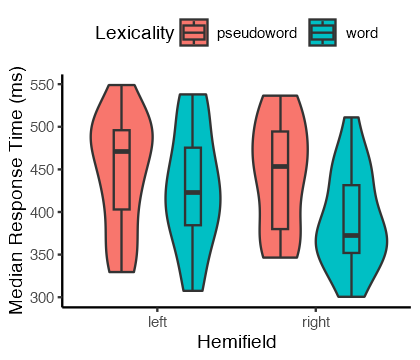

In [57]:
participant_avgs |>
  ggplot(aes(side, median_rt, fill=lexicality)) +
  geom_violin() +
  geom_boxplot(width=0.2, position=position_dodge(width=0.9)) +
  labs(x = "Hemifield", y = "Median Response Time (ms)", fill = "Lexicality")